# MiniProject 1 - Text Analysis

**Name:** David Long\
**Class:** COSC545

### Research Question
Are there significant vocabulary differences between hard and soft science fiction, despite being the same genre?

### Goals for MiniProject1
* Compare two works by Frank Herbert in his *Dune* series.
* Compare Herbert's works with Arthur C. Clarke's *2001: A Space Odyssey*.
* Analyze the vocabulary differences between soft science fiction and hard science fiction writers (Observe the fantastical verbiage in the former and the technical jargon in the latter).

### Books
* *Dune* by Frank Herbert
* *Dune: Messiah* by Frank Herbert
* *2001: A Space Odyssey* by Arthur C. Clarke

## 1. PDF Text Extraction and Cleaning

Following the same word-frequency pipeline as `MiniProject1.ipynb` (clean → tokenize → strip
punctuation/numbers → drop stopwords → count), adapted for PDF sources instead of URLs/`.txt` files.

### 1.1 Imports + Stopwords

In [1]:
import re
from collections import Counter
import operator
import nltk
from pypdf import PdfReader
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

nltk.download('stopwords', quiet=True)

# Top 100 most common English words (https://en.wikipedia.org/wiki/Most_common_words_in_English),
# on top of NLTK's stopword list.
common_english_words = [
    'the', 'be', 'to', 'of', 'and', 'a', 'in', 'that', 'have', 'i', 'it', 'for', 'not', 'on',
    'with', 'he', 'as', 'you', 'do', 'at', 'this', 'but', 'his', 'by', 'from', 'they', 'we',
    'say', 'her', 'she', 'or', 'an', 'will', 'my', 'one', 'all', 'would', 'there', 'their',
    'what', 'so', 'up', 'out', 'if', 'about', 'who', 'get', 'which', 'go', 'me', 'when', 'make',
    'can', 'like', 'time', 'no', 'just', 'him', 'know', 'take', 'people', 'into', 'year', 'your',
    'good', 'some', 'could', 'them', 'see', 'other', 'than', 'then', 'now', 'look', 'only',
    'come', 'its', 'over', 'think', 'also', 'back', 'after', 'use', 'two', 'how', 'our', 'work',
    'first', 'well', 'way', 'even', 'new', 'want', 'because', 'any', 'these', 'give', 'day',
    'most', 'us',
]

stop_words = set(nltk.corpus.stopwords.words('english') + common_english_words + [
    'ut', "'re", '.', ',', '--', "'s", '?', ')', '(', ':', "'",
    '"', '-', '}', '{', '&', '|', '—'
])

### 1.2 Extraction/Preprocess/Word Frequency Functions

In [2]:
# Concatenates the text of every page in a PDF into one string.
def extract_pdf_text(path):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

# Strips all non-alphanumeric characters and words that are only numbers.
def cleanWord(w):
    wn = re.sub('[^a-z0-9]', '', w)
    return re.sub('^[0-9]*$', "", wn)

# Returns the n most frequent words in the text, sorted ascending by frequency per 10,000
# regular (non-stopword) words, so books of very different lengths (e.g. Dune vs. Dune: Messiah)
# can be compared on equal footing.
def get_wf(text, n=15):
    wds = re.split('\s+', text.lower())
    wf = Counter(cleanWord(w) for w in wds)
    wf.pop('', None)
    for k in stop_words:
        wf.pop(k, None)
    tw = sum(wf.values())
    wfs = sorted(wf.items(), key=operator.itemgetter(1), reverse=True)
    ml = min(len(wfs), n)
    top = wfs[0:ml][::-1]
    normalized = [(word, count / tw * 10000) for word, count in top]
    return normalized, tw

### 1.3 Text Extraction + Preprocessing

In [3]:
books = {
    'Dune': 'books/Dune.pdf',
    'Dune: Messiah': 'books/Dune-Messiah.pdf',
    '2001: A Space Odyssey': 'books/2001-a-space-odyssey.pdf',
}

# Extracts the text of each book and computes the top-15 most frequent words.
texts = {title: extract_pdf_text(path) for title, path in books.items()}
word_freqs = {title: get_wf(text) for title, text in texts.items()}

# Prints the total number of regular (non-stopword) words counted in each book.
for title, (wfs, tw) in word_freqs.items():
    print('-' * 50)
    print(f"{title} ({tw} regular words)")
    print('-' * 50)
    print(f"Top {len(wfs)} words (frequency per 10,000 words):")
    for word, count in wfs:
        print(f"  {word}: {count:.2f}")
    print(' ')

--------------------------------------------------
Dune (100819 regular words)
--------------------------------------------------
Top 15 words (frequency per 10,000 words):
  water: 34.02
  kynes: 34.91
  hawat: 36.01
  stilgar: 36.30
  mother: 36.70
  asked: 37.29
  must: 37.99
  man: 44.44
  duke: 49.79
  fremen: 49.89
  baron: 53.56
  thought: 61.30
  jessica: 84.81
  paul: 152.75
  said: 225.26
 
--------------------------------------------------
Dune: Messiah (38378 regular words)
--------------------------------------------------
Top 15 words (frequency per 10,000 words):
  voice: 33.09
  felt: 38.30
  chani: 39.35
  irulan: 39.35
  ghola: 39.61
  must: 40.91
  thought: 42.99
  fremen: 48.73
  eyes: 48.99
  stilgar: 49.77
  asked: 53.16
  scytale: 53.16
  alia: 59.41
  paul: 182.66
  said: 226.69
 
--------------------------------------------------
2001: A Space Odyssey (30084 regular words)
--------------------------------------------------
Top 15 words (frequency per 10,000 wor

## 2. Plot Most Frequent Words (Normalized per 10,000 Words)

### 2.1 Dual Plot Function

In [4]:
# Plots two lists of word frequencies (per 10,000 words) side by side.
def plotTwoLists(wf_a, wf_b, label_a, label_b, title):
    f = plt.figure(figsize=(10, 6))
    f.suptitle(title, fontsize=20)

    ax1 = f.add_subplot(121)
    ax1.set_title(label_a, fontsize=14)
    ax1.set_xlabel('Frequency per 10,000 words', fontsize=10)
    ax1.set_yticks(range(len(wf_a)))
    ax1.set_yticklabels([x[0] for x in wf_a])
    ax1.barh(range(len(wf_a)), [x[1] for x in wf_a], align='center')
    pad_a = max((x[1] for x in wf_a), default=1) * 0.02
    for i, (_, rate) in enumerate(wf_a):
        ax1.text(rate - pad_a, i, f'{rate:.1f}', va='center', ha='right',
                  color='white', fontsize=9, fontweight='bold')

    ax2 = f.add_subplot(122)
    ax2.set_title(label_b, fontsize=14)
    ax2.set_xlabel('Frequency per 10,000 words', fontsize=10)
    ax2.set_yticks(range(len(wf_b)))
    ax2.set_yticklabels([x[0] for x in wf_b])
    ax2.barh(range(len(wf_b)), [x[1] for x in wf_b], align='center')
    pad_b = max((x[1] for x in wf_b), default=1) * 0.02
    for i, (_, rate) in enumerate(wf_b):
        ax2.text(rate - pad_b, i, f'{rate:.1f}', va='center', ha='right',
                  color='white', fontsize=9, fontweight='bold')

    plt.subplots_adjust(wspace=0.6)

### 2.2 Plotting Word Frequencies

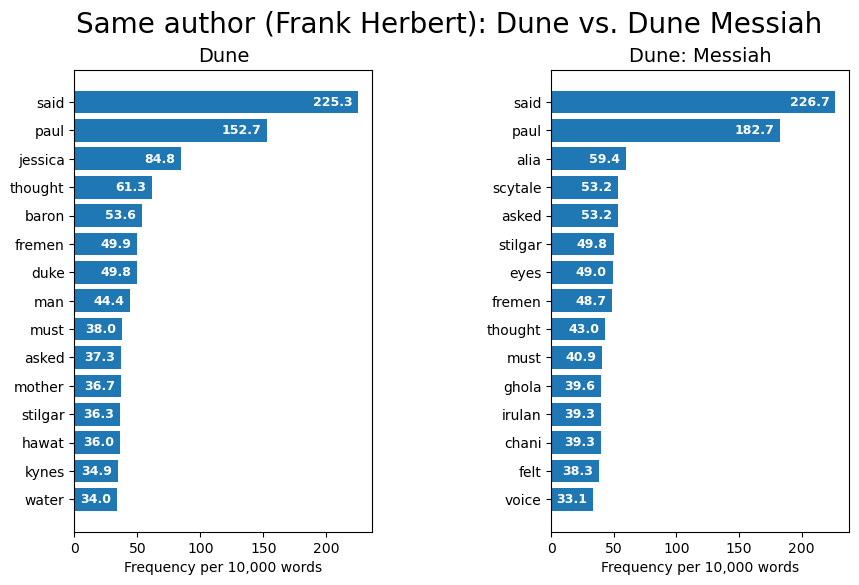

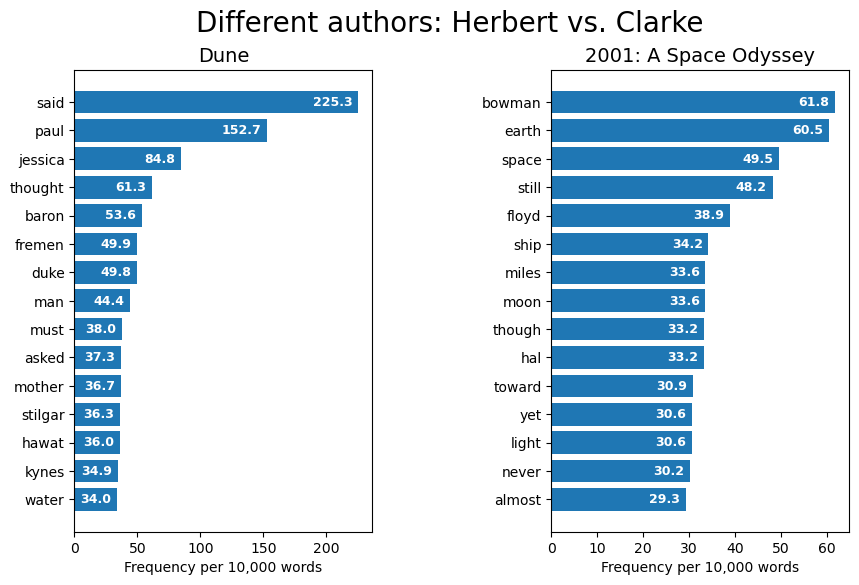

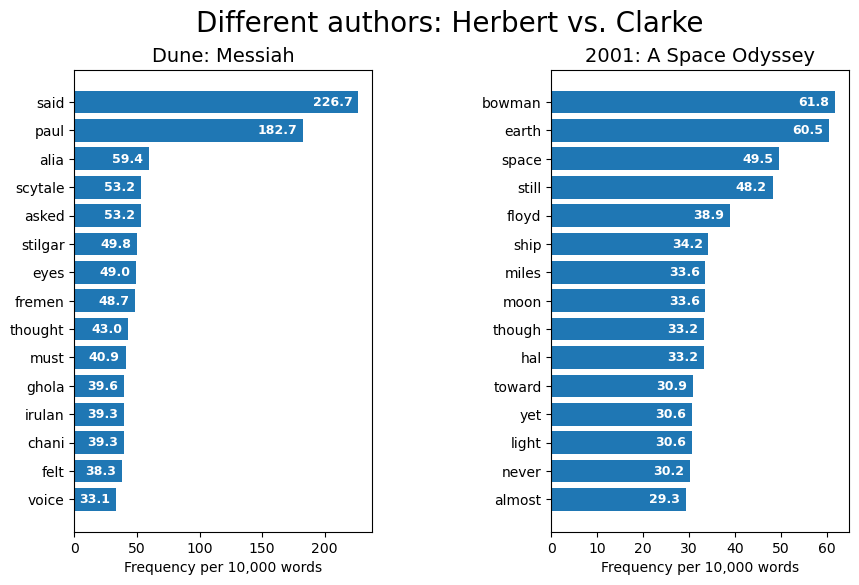

In [5]:
plotTwoLists(word_freqs['Dune'][0], word_freqs['Dune: Messiah'][0],
             'Dune', 'Dune: Messiah', 'Same author (Frank Herbert): Dune vs. Dune Messiah')

plotTwoLists(word_freqs['Dune'][0], word_freqs['2001: A Space Odyssey'][0],
             'Dune', '2001: A Space Odyssey', 'Different authors: Herbert vs. Clarke')

plotTwoLists(word_freqs['Dune: Messiah'][0], word_freqs['2001: A Space Odyssey'][0],
             'Dune: Messiah', '2001: A Space Odyssey', 'Different authors: Herbert vs. Clarke')

## 3. Cosine Similarity Between Books
Cosine similarity gives a single number summarizing how similar two books' overall vocabulary usage is. It's computed over each book's full (stopword-filtered) word-frequency vector.

### 3.1 Full-Vocabulary Word Frequencies

In [6]:
# Full (non-truncated) stopword-filtered word-frequency counts for each book, reusing the
# same cleaning as get_wf but keeping every word instead of just the top n.
def full_word_freq(text):
    wds = re.split('\s+', text.lower())
    wf = Counter(cleanWord(w) for w in wds)
    wf.pop('', None)
    for k in stop_words:
        wf.pop(k, None)
    return wf

full_freqs = {title: full_word_freq(text) for title, text in texts.items()}

### 3.2 Cosine Similarity Matrix

In [7]:
import pandas as pd

# Cosine similarity between two books' word-frequency vectors, aligned over their combined
# vocabulary (a word missing from one book counts as 0 there). 1.0 = identical relative word
# usage, 0.0 = no shared vocabulary.
def cosine_similarity(freq_a, freq_b):
    vocab = set(freq_a) | set(freq_b)
    va = np.array([freq_a[w] for w in vocab], dtype=float)
    vb = np.array([freq_b[w] for w in vocab], dtype=float)
    return np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))

titles = list(full_freqs.keys())
sim_matrix = pd.DataFrame(
    [[cosine_similarity(full_freqs[t1], full_freqs[t2]) for t2 in titles] for t1 in titles],
    index=titles, columns=titles,
)
sim_matrix.round(4)

,Dune,Dune: Messiah,2001: A Space Odyssey
Dune,1.0000,0.8540,0.3625
Dune: Messiah,0.8540,1.0000,0.3452
2001: A Space Odyssey,0.3625,0.3452,1.0000


### 3.3 Similarity Heatmap

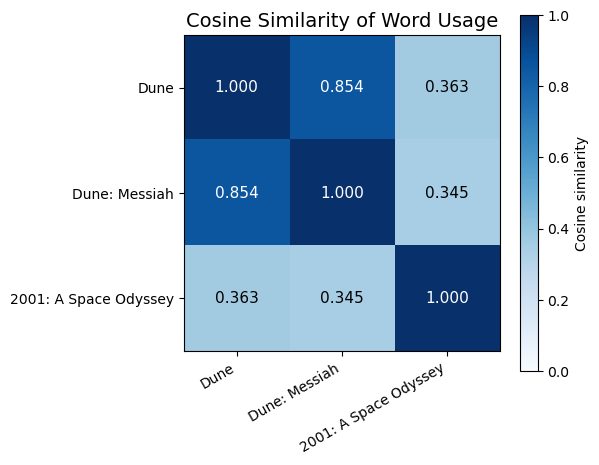

In [8]:
# Visualize the similarity matrix as a heatmap.
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim_matrix.values, cmap='Blues', vmin=0, vmax=1)

ax.set_xticks(range(len(titles)))
ax.set_xticklabels(titles, rotation=30, ha='right')
ax.set_yticks(range(len(titles)))
ax.set_yticklabels(titles)

for i in range(len(titles)):
    for j in range(len(titles)):
        value = sim_matrix.values[i, j]
        color = 'white' if value > 0.5 else 'black'
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', color=color, fontsize=11)

ax.set_title('Cosine Similarity of Word Usage', fontsize=14)
fig.colorbar(im, ax=ax, label='Cosine similarity')
plt.tight_layout()
plt.show()

## 4. Observations
1. Cosine similarity between the two *Dune* books (**0.854**) is more than double the similarity between either *Dune* book and *2001: A Space Odyssey* (**0.36/0.35**), suggesting that same-author vocabulary usage is more consistent than cross-author.
2. Top-word lists barely overlap between any of the books, so using cosine similarity across the full vocabulary of each book provides a better insight into how similar they may be to one another.
3. *2001*'s top words are more aligned with physical and spatial descriptions (space, earth, moon, miles, ship) while *Dune*'s are towards political and social nouns (duke, baron, mother) and *Messiah*'s are towards introspective words (voice, felt, eyes), which supports the fantastical verbiage vs. technical jargon framing.
4. "said" and "Paul" in both *Dune* books have a near-identical normalized rate, which is interesting considering the books vary quite significantly in length. This shows that Herbert's style is quite consistent across texts, regardless of the texts.

### 5. Conclusion
This analysis would support the idea that there are differences between hard and soft science fiction texts, though the scope of this analysis is very limited and might benefit from future analysis with more texts.